<a href="https://colab.research.google.com/github/shmehjabeen/Python-Project-Retail-and-Wherehouse-Sales/blob/main/Retail_Sales_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail & Warehouse Sales Report :

# 1. Import libraries and load the dataset

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

file_path = "/content/Retail and wherehouse Sale.csv"
df = pd.read_csv(file_path)
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (30000, 9)


,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.00,0.00,2.00
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.00,1.00,4.00
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.00,0.00,1.00
3,2020,1,LANTERNA DISTRIBUTORS INC,100145,SCHLINK HAUS KABINETT - 750ML,WINE,0.00,0.00,1.00
4,2020,1,DIONYSOS IMPORTS INC,100293,SANTORINI GAVALA WHITE - 750ML,WINE,0.82,0.00,0.00


# 2. Basic Data Understanding

In [46]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn Names:")
print(df.columns.tolist())
print("\nData Types:")
print(df.dtypes)
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe(include="all"))

Number of rows: 30000
Number of columns: 9

Column Names:
['YEAR', 'MONTH', 'SUPPLIER', 'ITEM CODE', 'ITEM DESCRIPTION', 'ITEM TYPE', 'RETAIL SALES', 'RETAIL TRANSFERS', 'WAREHOUSE SALES']

Data Types:
YEAR                  int64
MONTH                 int64
SUPPLIER             object
ITEM CODE            object
ITEM DESCRIPTION     object
ITEM TYPE            object
RETAIL SALES        float64
RETAIL TRANSFERS    float64
WAREHOUSE SALES     float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   YEAR              30000 non-null  int64  
 1   MONTH             30000 non-null  int64  
 2   SUPPLIER          29967 non-null  object 
 3   ITEM CODE         30000 non-null  object 
 4   ITEM DESCRIPTION  30000 non-null  object 
 5   ITEM TYPE         30000 non-null  object 
 6   RETAIL SALES      299

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
count,"30,000.00","30,000.00",29967,30000,30000,30000,"29,999.00","30,000.00","30,000.00"
unique,NaN,NaN,290,15668,15732,8,NaN,NaN,NaN
top,NaN,NaN,"THE COUNTRY VINTNER, LLC DBA WINEBOW",16225,TENTH WARD DIST CO CARAWAY RYE - 750ML,WINE,NaN,NaN,NaN
freq,NaN,NaN,2041,4,5,18680,NaN,NaN,NaN
mean,"2,020.00",3.91,NaN,NaN,NaN,NaN,6.94,6.59,27.43
std,0.00,2.84,NaN,NaN,NaN,NaN,33.08,27.88,272.17
min,"2,020.00",1.00,NaN,NaN,NaN,NaN,-0.42,-6.00,"-3,999.00"
25%,"2,020.00",1.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00
50%,"2,020.00",3.00,NaN,NaN,NaN,NaN,0.16,0.00,1.00
75%,"2,020.00",7.00,NaN,NaN,NaN,NaN,2.92,3.00,6.00


# 3. Check Missing Values

,Missing Count,Missing %
SUPPLIER,33,0.11
RETAIL SALES,1,0.00
YEAR,0,0.00
ITEM CODE,0,0.00
MONTH,0,0.00
ITEM DESCRIPTION,0,0.00
ITEM TYPE,0,0.00
RETAIL TRANSFERS,0,0.00
WAREHOUSE SALES,0,0.00


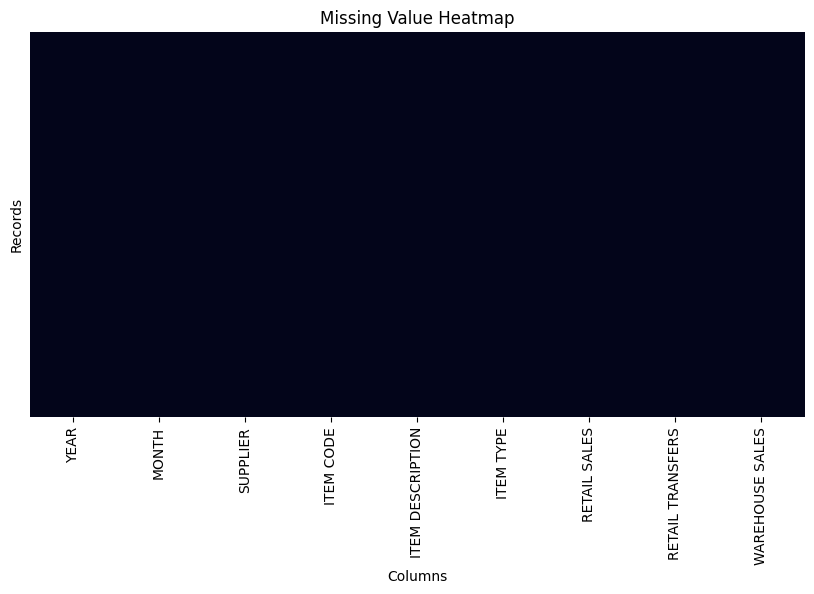

In [47]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": df.isnull().mean() * 100
}).sort_values("Missing Count", ascending=False)

display(missing)

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Value Heatmap")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.show()

In [48]:
numeric_columns = [
    "SUPPLIER",

]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(0)

In [49]:
print(df.isnull().sum())

YEAR                0
MONTH               0
SUPPLIER            0
ITEM CODE           0
ITEM DESCRIPTION    0
ITEM TYPE           0
RETAIL SALES        1
RETAIL TRANSFERS    0
WAREHOUSE SALES     0
dtype: int64


In [50]:
numeric_columns = [
    "RETAIL SALES",

]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(0)

In [51]:
print(df.isnull().sum())

YEAR                0
MONTH               0
SUPPLIER            0
ITEM CODE           0
ITEM DESCRIPTION    0
ITEM TYPE           0
RETAIL SALES        0
RETAIL TRANSFERS    0
WAREHOUSE SALES     0
dtype: int64


# 4. Remove Duplicate Records

In [52]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Shape after removing duplicates: (30000, 9)


# 5. Clean Column Names

In [53]:
df.columns = (
    df.columns
    .str.strip()
    .str.upper()
    .str.replace(" ", "_", regex=False)
)
print(df.columns.tolist())

['YEAR', 'MONTH', 'SUPPLIER', 'ITEM_CODE', 'ITEM_DESCRIPTION', 'ITEM_TYPE', 'RETAIL_SALES', 'RETAIL_TRANSFERS', 'WAREHOUSE_SALES']


# 6. Convert Numeric Columns

In [54]:
numeric_columns = ["RETAIL_SALES", "RETAIL_TRANSFERS", "WAREHOUSE_SALES"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_columns].dtypes)

RETAIL_SALES        float64
RETAIL_TRANSFERS    float64
WAREHOUSE_SALES     float64
dtype: object


# 7. Date / Month Analysis

In [55]:
df["DATE"] = pd.to_datetime(
    df["YEAR"].astype(str) + "-" +
    df["MONTH"].astype(str) + "-01",
    errors="coerce"
)
df["MONTH_NAME"] = df["DATE"].dt.month_name()
print(df[["YEAR", "MONTH", "DATE", "MONTH_NAME"]].head())

   YEAR  MONTH       DATE MONTH_NAME
0  2020      1 2020-01-01    January
1  2020      1 2020-01-01    January
2  2020      1 2020-01-01    January
3  2020      1 2020-01-01    January
4  2020      1 2020-01-01    January


# 8. Create Total Activity / Sales KPI

In [56]:
df["TOTAL_ACTIVITY"] = (
    df["RETAIL_SALES"].fillna(0)
    + df["RETAIL_TRANSFERS"].fillna(0)
    + df["WAREHOUSE_SALES"].fillna(0)
)
print("Total Activity:", df["TOTAL_ACTIVITY"].sum())

Total Activity: 1228939.6099999999


# 9. Executive KPI Analysis

In [57]:
total_retail_sales = df["RETAIL_SALES"].sum()
total_transfers = df["RETAIL_TRANSFERS"].sum()
total_warehouse = df["WAREHOUSE_SALES"].sum()
total_activity = df["TOTAL_ACTIVITY"].sum()
unique_suppliers = df["SUPPLIER"].nunique()
unique_items = df["ITEM_CODE"].nunique()
unique_categories = df["ITEM_TYPE"].nunique()

print("=" * 60)
print("EXECUTIVE KPI REPORT")
print("=" * 60)
print(f"Total Retail Sales : {total_retail_sales:,.2f}")
print(f"Total Retail Transfers : {total_transfers:,.2f}")
print(f"Total Warehouse Sales : {total_warehouse:,.2f}")
print(f"Total Activity : {total_activity:,.2f}")
print(f"Unique Suppliers : {unique_suppliers:,}")
print(f"Unique SKUs : {unique_items:,}")
print(f"Item Categories : {unique_categories:,}")

EXECUTIVE KPI REPORT
Total Retail Sales : 208,186.94
Total Retail Transfers : 197,821.74
Total Warehouse Sales : 822,930.93
Total Activity : 1,228,939.61
Unique Suppliers : 1
Unique SKUs : 15,668
Item Categories : 8


# 10. Calculate Channel Contribution %

,Channel,Activity,Percentage
0,Retail Sales,"208,186.94",16.94
1,Retail Transfers,"197,821.74",16.10
2,Warehouse Sales,"822,930.93",66.96


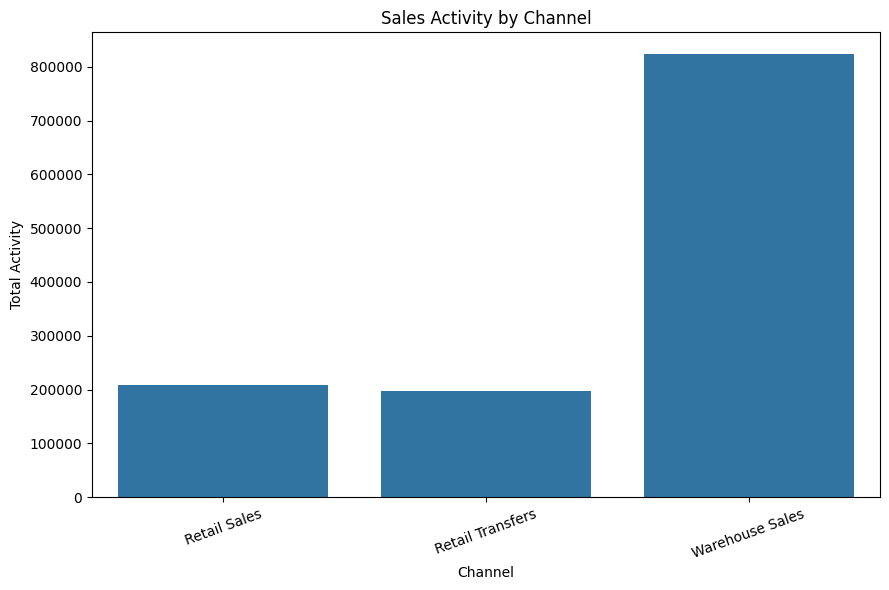

In [58]:
channel_summary = pd.DataFrame({
    "Channel": ["Retail Sales", "Retail Transfers", "Warehouse Sales"],
    "Activity": [total_retail_sales, total_transfers, total_warehouse]
})
channel_summary["Percentage"] = (
    channel_summary["Activity"] / channel_summary["Activity"].sum()
) * 100
display(channel_summary)

plt.figure(figsize=(9, 6))
sns.barplot(data=channel_summary, x="Channel", y="Activity")
plt.title("Sales Activity by Channel")
plt.xlabel("Channel")
plt.ylabel("Total Activity")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 11. Monthly Sales Analysis

In [59]:
monthly = (
    df.groupby("MONTH_NAME")
    .agg({
        "RETAIL_SALES": "sum",
        "RETAIL_TRANSFERS": "sum",
        "WAREHOUSE_SALES": "sum",
        "TOTAL_ACTIVITY": "sum"
    })
    .reset_index()
)

month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
monthly["MONTH_NAME"] = pd.Categorical(
    monthly["MONTH_NAME"], categories=month_order, ordered=True
)
monthly = monthly.sort_values("MONTH_NAME")
display(monthly)

,MONTH_NAME,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES,TOTAL_ACTIVITY
0,January,"74,318.77","75,997.35","284,114.72","434,430.84"
2,March,"34,523.90","34,505.08","113,305.22","182,334.20"
1,July,"94,538.96","82,706.57","418,094.42","595,339.95"
3,September,"4,805.31","4,612.74","7,416.57","16,834.62"


# 12. Monthly Trend Chart

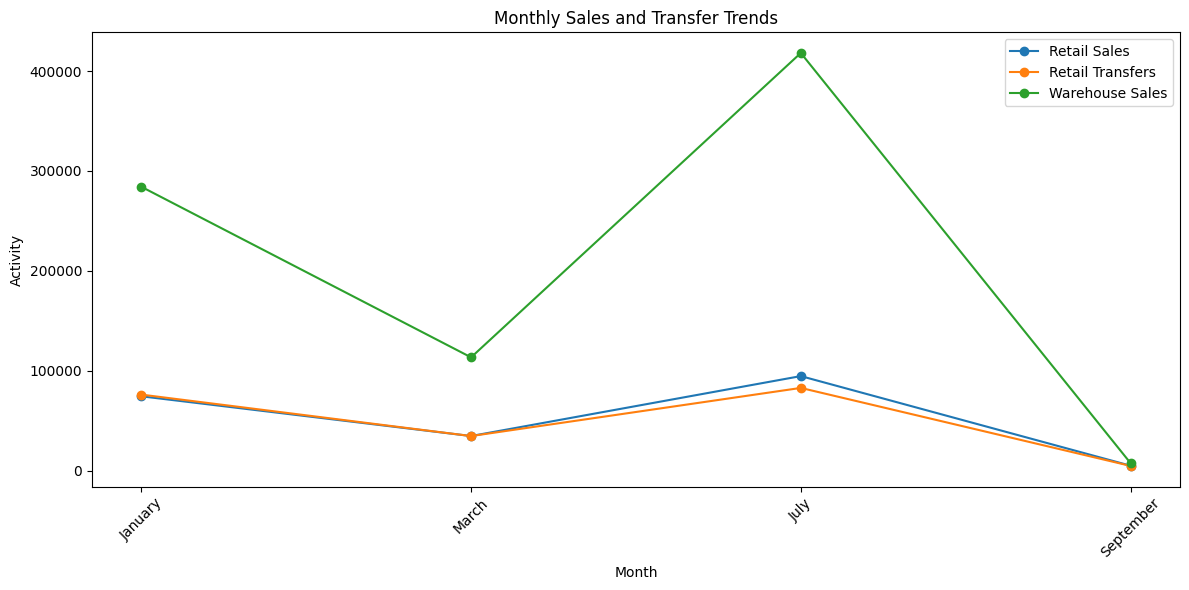

In [60]:
plt.figure(figsize=(12, 6))
plt.plot(monthly["MONTH_NAME"], monthly["RETAIL_SALES"], marker="o", label="Retail Sales")
plt.plot(monthly["MONTH_NAME"], monthly["RETAIL_TRANSFERS"], marker="o", label="Retail Transfers")
plt.plot(monthly["MONTH_NAME"], monthly["WAREHOUSE_SALES"], marker="o", label="Warehouse Sales")
plt.title("Monthly Sales and Transfer Trends")
plt.xlabel("Month")
plt.ylabel("Activity")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# 13. Find Best and Worst Month

In [61]:
best_month = monthly.loc[monthly["TOTAL_ACTIVITY"].idxmax()]
worst_month = monthly.loc[monthly["TOTAL_ACTIVITY"].idxmin()]

print("BEST MONTH")
print(best_month)
print("\nWORST MONTH")
print(worst_month)

BEST MONTH
MONTH_NAME               July
RETAIL_SALES        94,538.96
RETAIL_TRANSFERS    82,706.57
WAREHOUSE_SALES    418,094.42
TOTAL_ACTIVITY     595,339.95
Name: 1, dtype: object

WORST MONTH
MONTH_NAME          September
RETAIL_SALES         4,805.31
RETAIL_TRANSFERS     4,612.74
WAREHOUSE_SALES      7,416.57
TOTAL_ACTIVITY      16,834.62
Name: 3, dtype: object


# 14. Month-over-Month Growth

In [62]:
monthly["MoM_Growth_%"] = monthly["TOTAL_ACTIVITY"].pct_change() * 100
display(monthly)

,MONTH_NAME,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES,TOTAL_ACTIVITY,MoM_Growth_%
0,January,"74,318.77","75,997.35","284,114.72","434,430.84",NaN
2,March,"34,523.90","34,505.08","113,305.22","182,334.20",-58.03
1,July,"94,538.96","82,706.57","418,094.42","595,339.95",226.51
3,September,"4,805.31","4,612.74","7,416.57","16,834.62",-97.17


# 15. Item Category Analysis

In [63]:
category = (
    df.groupby("ITEM_TYPE")
    .agg({
        "RETAIL_SALES": "sum",
        "RETAIL_TRANSFERS": "sum",
        "WAREHOUSE_SALES": "sum",
        "TOTAL_ACTIVITY": "sum"
    })
    .sort_values("TOTAL_ACTIVITY", ascending=False)
    .reset_index()
)
category["Contribution_%"] = (
    category["TOTAL_ACTIVITY"] / category["TOTAL_ACTIVITY"].sum()
) * 100
display(category)

,ITEM_TYPE,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES,TOTAL_ACTIVITY,Contribution_%
0,BEER,"59,538.76","55,729.83","697,279.68","812,548.27",66.12
1,WINE,"59,688.84","58,629.13","119,459.93","237,777.90",19.35
2,LIQUOR,"81,742.85","79,599.70","8,796.90","170,139.45",13.84
3,NON-ALCOHOL,"6,824.62","2,934.08","2,438.42","12,197.12",0.99
4,KEGS,0.00,0.00,"8,400.00","8,400.00",0.68
5,STR_SUPPLIES,345.60,895.00,0.00,"1,240.60",0.10
6,REF,46.27,34.00,"-1,329.00","-1,248.73",-0.10
7,DUNNAGE,0.00,0.00,"-12,115.00","-12,115.00",-0.99


# 16. Category Bar Chart

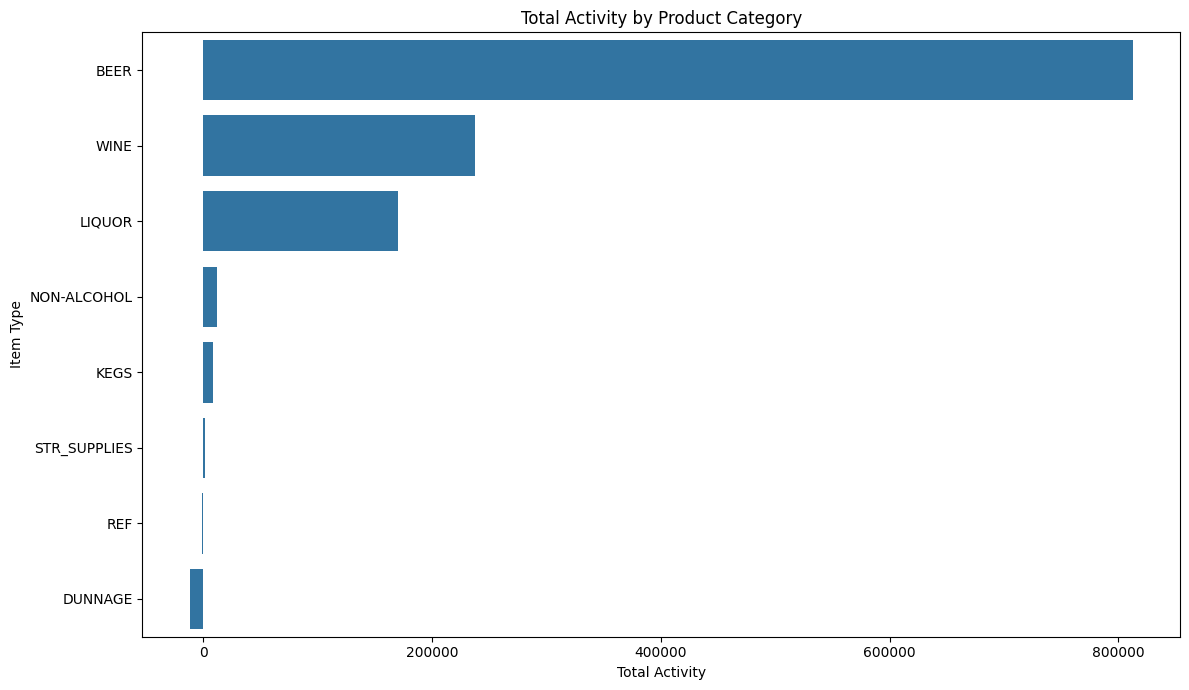

In [64]:
plt.figure(figsize=(12, 7))
sns.barplot(data=category, y="ITEM_TYPE", x="TOTAL_ACTIVITY")
plt.title("Total Activity by Product Category")
plt.xlabel("Total Activity")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

# 17. Category Contribution Pie Chart

Category DataFrame before plotting (check for negative values):


,ITEM_TYPE,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES,TOTAL_ACTIVITY,Contribution_%
0,BEER,"59,538.76","55,729.83","697,279.68","812,548.27",66.12
1,WINE,"59,688.84","58,629.13","119,459.93","237,777.90",19.35
2,LIQUOR,"81,742.85","79,599.70","8,796.90","170,139.45",13.84
3,NON-ALCOHOL,"6,824.62","2,934.08","2,438.42","12,197.12",0.99
4,KEGS,0.00,0.00,"8,400.00","8,400.00",0.68
5,STR_SUPPLIES,345.60,895.00,0.00,"1,240.60",0.10
6,REF,46.27,34.00,"-1,329.00","-1,248.73",-0.10
7,DUNNAGE,0.00,0.00,"-12,115.00","-12,115.00",-0.99


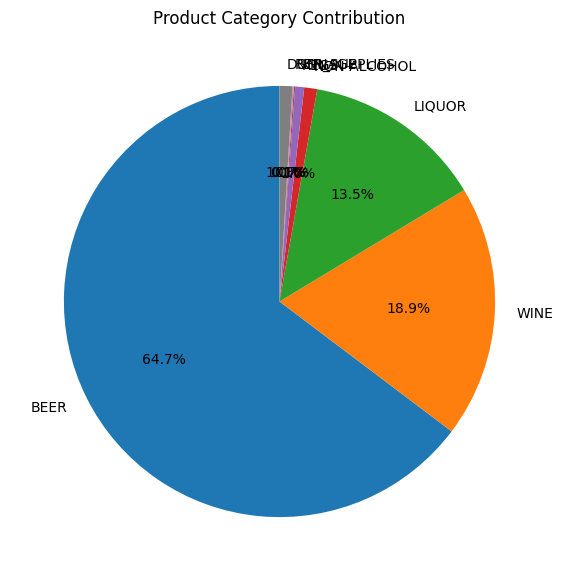

In [65]:
print("Category DataFrame before plotting (check for negative values):")
display(category)

plt.figure(figsize=(7, 7))
plt.pie(
    category["TOTAL_ACTIVITY"].abs(), # Use absolute values for plotting
    labels=category["ITEM_TYPE"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Product Category Contribution")
plt.show()

# 18. Top 10 Suppliers

In [66]:
supplier = (
    df.groupby("SUPPLIER")
    .agg({
        "RETAIL_SALES": "sum",
        "RETAIL_TRANSFERS": "sum",
        "WAREHOUSE_SALES": "sum",
        "TOTAL_ACTIVITY": "sum"
    })
    .sort_values("TOTAL_ACTIVITY", ascending=False)
    .reset_index()
)
supplier["Contribution_%"] = (
    supplier["TOTAL_ACTIVITY"] / supplier["TOTAL_ACTIVITY"].sum()
) * 100
top10_suppliers = supplier.head(10)
display(top10_suppliers)

,SUPPLIER,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES,TOTAL_ACTIVITY,Contribution_%
0,0.00,"208,186.94","197,821.74","822,930.93","1,228,939.61",100.00


# 19. Top 10 Supplier Chart

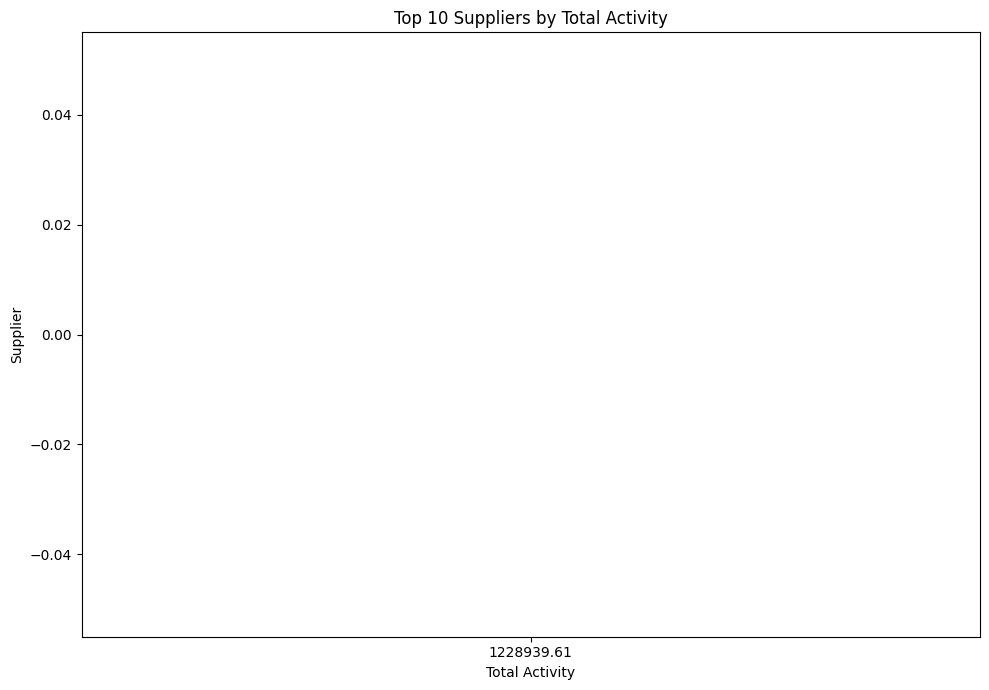

In [67]:
plt.figure(figsize=(10, 7))
sns.barplot(data=top10_suppliers, y="SUPPLIER", x="TOTAL_ACTIVITY")
plt.title("Top 10 Suppliers by Total Activity")
plt.xlabel("Total Activity")
plt.ylabel("Supplier")
plt.tight_layout()
plt.show()

# 20. Supplier Concentration — Top 5 and Top 10

In [68]:
top5_supplier_share = (
    supplier.head(5)["TOTAL_ACTIVITY"].sum() / supplier["TOTAL_ACTIVITY"].sum()
) * 100
top10_supplier_share = (
    supplier.head(10)["TOTAL_ACTIVITY"].sum() / supplier["TOTAL_ACTIVITY"].sum()
) * 100

print(f"Top 5 Supplier Contribution : {top5_supplier_share:.2f}%")
print(f"Top 10 Supplier Contribution: {top10_supplier_share:.2f}%")

Top 5 Supplier Contribution : 100.00%
Top 10 Supplier Contribution: 100.00%


# 21. Top 10 Products / SKUs

In [69]:
sku = (
    df.groupby(["ITEM_CODE", "ITEM_DESCRIPTION"])
    .agg({
        "RETAIL_SALES": "sum",
        "RETAIL_TRANSFERS": "sum",
        "WAREHOUSE_SALES": "sum",
        "TOTAL_ACTIVITY": "sum"
    })
    .sort_values("TOTAL_ACTIVITY", ascending=False)
    .reset_index()
)
sku["Contribution_%"] = (
    sku["TOTAL_ACTIVITY"] / sku["TOTAL_ACTIVITY"].sum()
) * 100
top10_skus = sku.head(10)
display(top10_skus)

,ITEM_CODE,ITEM_DESCRIPTION,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES,TOTAL_ACTIVITY,Contribution_%
0,23445,CORONA EXTRA LOOSE NR - 12OZ,"2,845.00","2,934.00","43,330.50","49,109.50",4.00
1,23886,HEINEKEN LOOSE NR - 12OZ,"2,096.00","2,097.00","22,599.88","26,792.88",2.18
2,96750,CORONA EXTRA 2/12 NR - 12OZ,"1,105.00",961.00,"19,016.50","21,082.50",1.72
3,25883,MODELO ESPECIAL 24 LOOSE NR - 12OZ,795.00,820.00,"19,355.00","20,970.00",1.71
4,96970,HEINEKEN 2/12 NR - 12OZ,806.23,634.50,"14,495.67","15,936.40",1.30
5,90590,MILLER LITE 30PK CAN - 12OZ,"1,045.00",766.00,"11,648.40","13,459.40",1.10
6,23777,MODELO ESPECIAL SUITCASE CANS - 12OZ,360.00,333.00,"12,399.84","13,092.84",1.07
7,23314,CORONA EXTRA 18PK NR - 12OZ,11.00,12.00,"10,950.72","10,973.72",0.89
8,96741,CORONA EXTRA 4/6 NR - 12OZ,490.83,451.00,"9,438.21","10,380.04",0.84
9,90468,BUD LIGHT 30PK CAN,958.00,821.00,"8,583.97","10,362.97",0.84


# 22. Top 10 SKU Chart

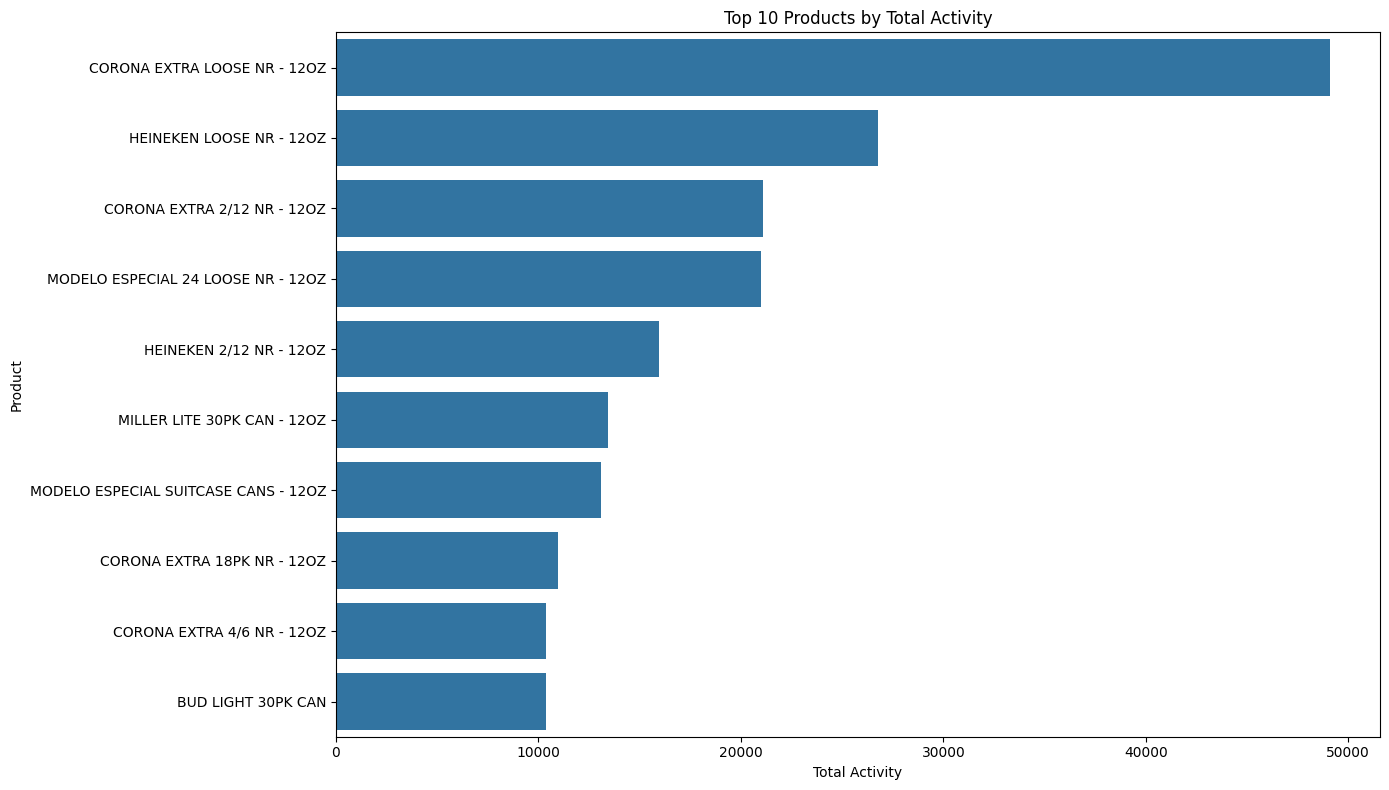

In [70]:
plt.figure(figsize=(14, 8))
sns.barplot(data=top10_skus, y="ITEM_DESCRIPTION", x="TOTAL_ACTIVITY")
plt.title("Top 10 Products by Total Activity")
plt.xlabel("Total Activity")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# 23. SKU Pareto Analysis

,ITEM_CODE,ITEM_DESCRIPTION,TOTAL_ACTIVITY,Contribution_%,Cumulative_%
0,23445,CORONA EXTRA LOOSE NR - 12OZ,"49,109.50",4.00,4.00
1,23886,HEINEKEN LOOSE NR - 12OZ,"26,792.88",2.18,6.18
2,96750,CORONA EXTRA 2/12 NR - 12OZ,"21,082.50",1.72,7.89
3,25883,MODELO ESPECIAL 24 LOOSE NR - 12OZ,"20,970.00",1.71,9.60
4,96970,HEINEKEN 2/12 NR - 12OZ,"15,936.40",1.30,10.89
5,90590,MILLER LITE 30PK CAN - 12OZ,"13,459.40",1.10,11.99
6,23777,MODELO ESPECIAL SUITCASE CANS - 12OZ,"13,092.84",1.07,13.06
7,23314,CORONA EXTRA 18PK NR - 12OZ,"10,973.72",0.89,13.95
8,96741,CORONA EXTRA 4/6 NR - 12OZ,"10,380.04",0.84,14.79
9,90468,BUD LIGHT 30PK CAN,"10,362.97",0.84,15.64


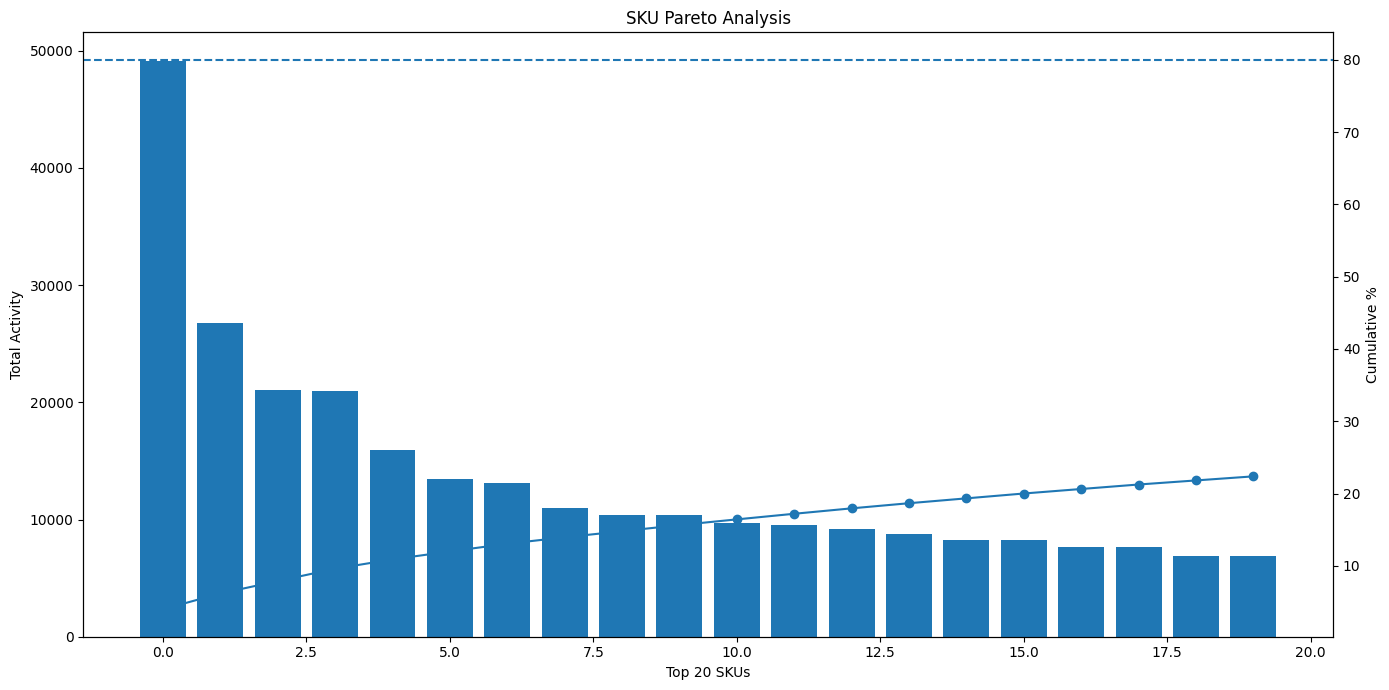

In [71]:
sku_pareto = sku.copy()
sku_pareto["Cumulative_%"] = (
    sku_pareto["TOTAL_ACTIVITY"].cumsum()
    / sku_pareto["TOTAL_ACTIVITY"].sum()
) * 100
display(sku_pareto[
    ["ITEM_CODE", "ITEM_DESCRIPTION", "TOTAL_ACTIVITY", "Contribution_%", "Cumulative_%"]
].head(20))

top20 = sku_pareto.head(20)
fig, ax1 = plt.subplots(figsize=(14, 7))
ax1.bar(range(len(top20)), top20["TOTAL_ACTIVITY"])
ax1.set_xlabel("Top 20 SKUs")
ax1.set_ylabel("Total Activity")
ax2 = ax1.twinx()
ax2.plot(range(len(top20)), top20["Cumulative_%"], marker="o")
ax2.set_ylabel("Cumulative %")
ax2.axhline(80, linestyle="--")
plt.title("SKU Pareto Analysis")
plt.tight_layout()
plt.show()

# 24. Supplier Pareto Analysis

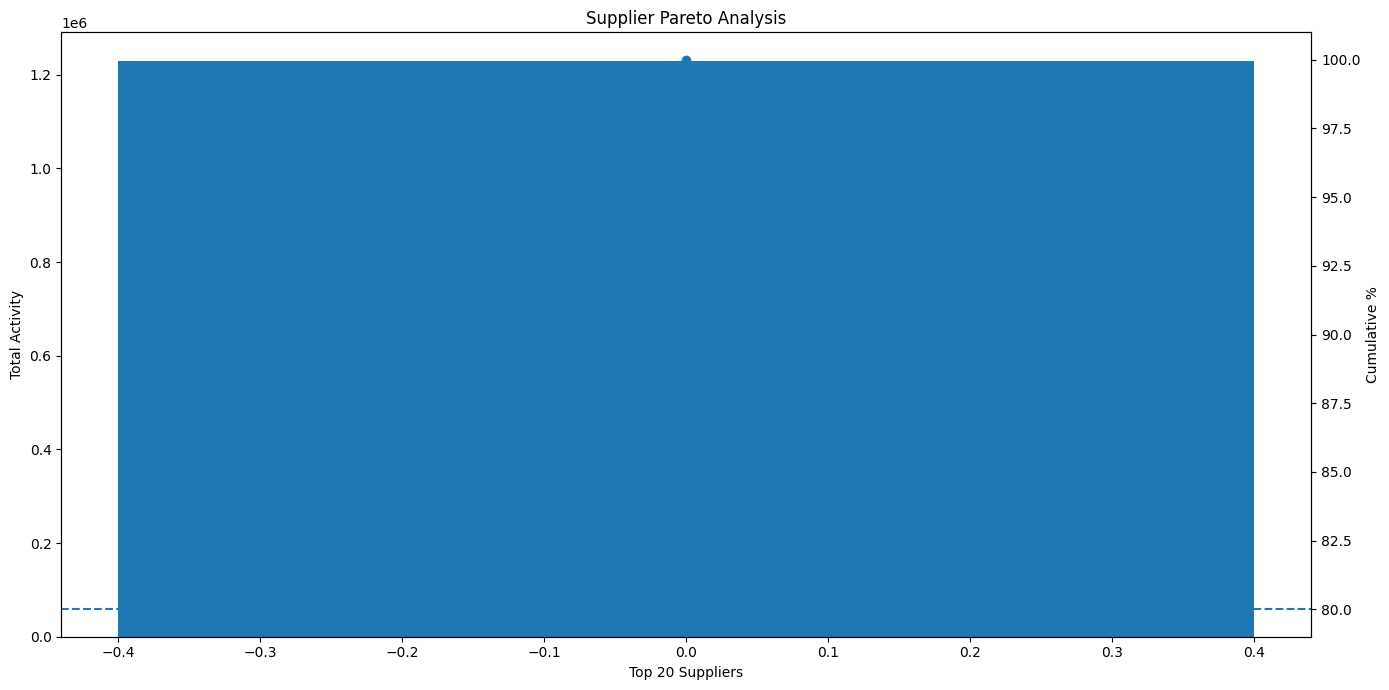

In [72]:
supplier_pareto = supplier.copy()
supplier_pareto["Cumulative_%"] = (
    supplier_pareto["TOTAL_ACTIVITY"].cumsum()
    / supplier_pareto["TOTAL_ACTIVITY"].sum()
) * 100

top20_suppliers = supplier_pareto.head(20)
fig, ax1 = plt.subplots(figsize=(14, 7))
ax1.bar(range(len(top20_suppliers)), top20_suppliers["TOTAL_ACTIVITY"])
ax1.set_xlabel("Top 20 Suppliers")
ax1.set_ylabel("Total Activity")
ax2 = ax1.twinx()
ax2.plot(range(len(top20_suppliers)), top20_suppliers["Cumulative_%"], marker="o")
ax2.set_ylabel("Cumulative %")
ax2.axhline(80, linestyle="--")
plt.title("Supplier Pareto Analysis")
plt.tight_layout()
plt.show()

# 25. Correlation Analysis

                  RETAIL_SALES  RETAIL_TRANSFERS  WAREHOUSE_SALES
RETAIL_SALES              1.00              0.84             0.49
RETAIL_TRANSFERS          0.84              1.00             0.54
WAREHOUSE_SALES           0.49              0.54             1.00


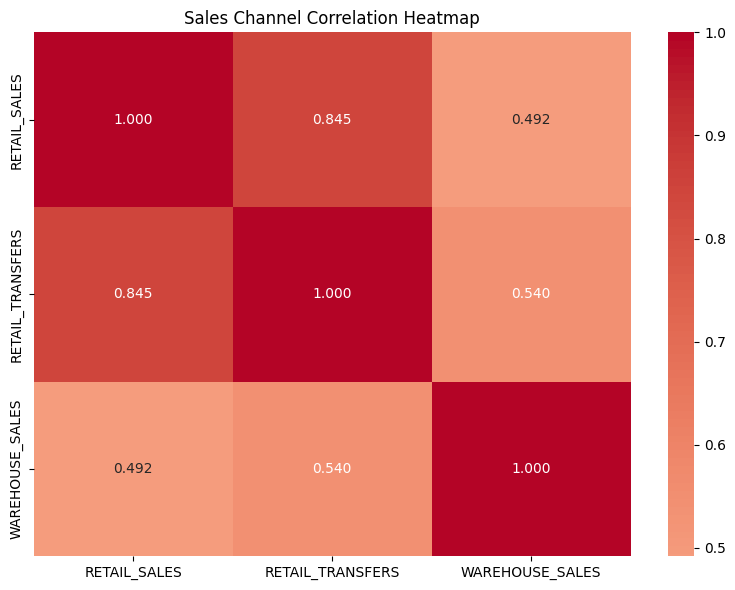

In [73]:
sales_columns = ["RETAIL_SALES", "RETAIL_TRANSFERS", "WAREHOUSE_SALES"]
correlation = df[sales_columns].corr()
print(correlation)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Sales Channel Correlation Heatmap")
plt.tight_layout()
plt.show()

# 26. Retail Sales vs Transfers Scatter Plot

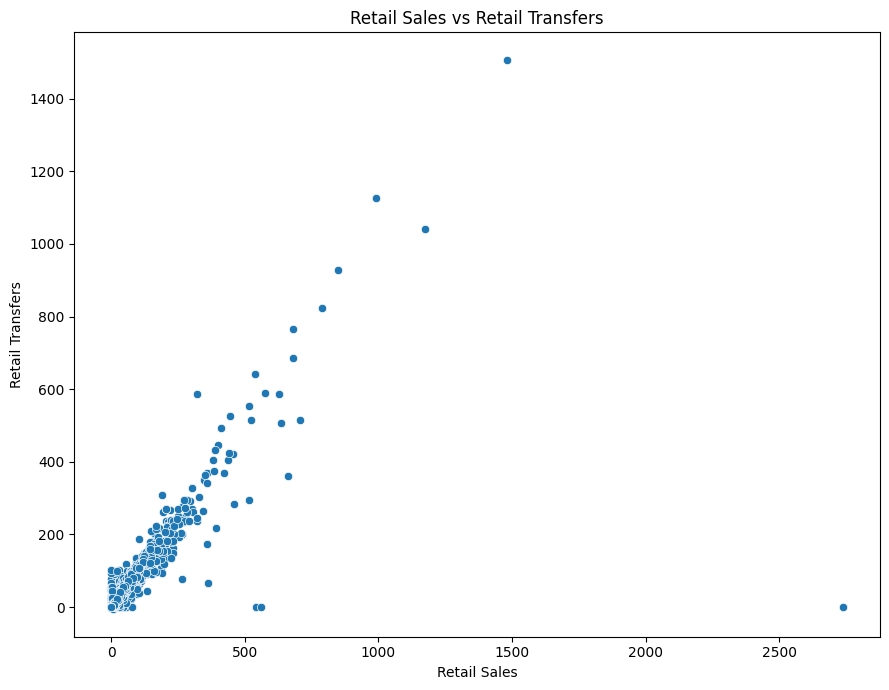

In [74]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x="RETAIL_SALES", y="RETAIL_TRANSFERS")
plt.title("Retail Sales vs Retail Transfers")
plt.xlabel("Retail Sales")
plt.ylabel("Retail Transfers")
plt.tight_layout()
plt.show()

# 27. Calculate Specific Correlations

In [75]:
retail_transfer_corr = df[["RETAIL_SALES", "RETAIL_TRANSFERS"]].corr().iloc[0, 1]
retail_warehouse_corr = df[["RETAIL_SALES", "WAREHOUSE_SALES"]].corr().iloc[0, 1]
transfer_warehouse_corr = df[["RETAIL_TRANSFERS", "WAREHOUSE_SALES"]].corr().iloc[0, 1]

print(f"Retail Sales vs Transfers : {retail_transfer_corr:.3f}")
print(f"Retail Sales vs Warehouse : {retail_warehouse_corr:.3f}")
print(f"Transfers vs Warehouse : {transfer_warehouse_corr:.3f}")

Retail Sales vs Transfers : 0.845
Retail Sales vs Warehouse : 0.492
Transfers vs Warehouse : 0.540


# 28. Zero Sales Analysis

In [76]:
zero_analysis = pd.DataFrame({
    "Metric": ["Retail Sales = 0", "Retail Transfers = 0", "Warehouse Sales = 0"],
    "Count": [
        (df["RETAIL_SALES"] == 0).sum(),
        (df["RETAIL_TRANSFERS"] == 0).sum(),
        (df["WAREHOUSE_SALES"] == 0).sum()
    ]
})
zero_analysis["Percentage"] = (zero_analysis["Count"] / len(df)) * 100
display(zero_analysis)

,Metric,Count,Percentage
0,Retail Sales = 0,13690,45.63
1,Retail Transfers = 0,19137,63.79
2,Warehouse Sales = 0,7928,26.43


# 29. Active vs Inactive SKU Analysis

In [77]:
sku_activity = df.groupby("ITEM_CODE")["TOTAL_ACTIVITY"].sum()
active_skus = sku_activity[sku_activity > 0].count()
inactive_skus = sku_activity[sku_activity == 0].count()
total_skus = len(sku_activity)

print("Total SKUs :", total_skus)
print("Active SKUs :", active_skus)
print("Inactive SKUs :", inactive_skus)
print(f"Active SKU Rate: {active_skus / total_skus * 100:.2f}%")

Total SKUs : 15668
Active SKUs : 15588
Inactive SKUs : 45
Active SKU Rate: 99.49%


# 30. Negative Transaction Analysis

In [78]:
negative_analysis = pd.DataFrame({
    "Metric": ["Negative Retail Sales", "Negative Retail Transfers", "Negative Warehouse Sales"],
    "Count": [
        (df["RETAIL_SALES"] < 0).sum(),
        (df["RETAIL_TRANSFERS"] < 0).sum(),
        (df["WAREHOUSE_SALES"] < 0).sum()
    ]
})
display(negative_analysis)

,Metric,Count
0,Negative Retail Sales,6
1,Negative Retail Transfers,16
2,Negative Warehouse Sales,76


# 31. Investigate Negative Transactions

In [79]:
negative_records = df[
    (df["RETAIL_SALES"] < 0) |
    (df["RETAIL_TRANSFERS"] < 0) |
    (df["WAREHOUSE_SALES"] < 0)
]
print("Number of records containing negative values:", len(negative_records))
display(negative_records[
    [
        "ITEM_CODE", "ITEM_DESCRIPTION", "ITEM_TYPE", "SUPPLIER",
        "RETAIL_SALES", "RETAIL_TRANSFERS", "WAREHOUSE_SALES"
    ]
].head(50))

Number of records containing negative values: 98


,ITEM_CODE,ITEM_DESCRIPTION,ITEM_TYPE,SUPPLIER,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES
405,1279,EMPTY WINE KEG - KEGS,DUNNAGE,0.00,0.00,0.00,-12.00
822,175,EMPTY 1/2 KEG (30.00),DUNNAGE,0.00,0.00,0.00,"-3,999.00"
1011,205,EMPTY 1/6 KEG (30.00),DUNNAGE,0.00,0.00,0.00,-934.00
1552,236502,J DE TELMONT SANS SOUFRE AJOUTE BRUT CHAMP - 7...,WINE,0.00,0.00,0.00,-1.00
2144,25049,ERDINGER HEFE WEISSE 50L 1/2K,KEGS,0.00,0.00,0.00,-1.00
2215,25738,PORT CITY MONUMENTAL IPA 4/6 12 OZ,BEER,0.00,3.25,-1.00,17.00
2305,26350,LEINENKUGEL SNOW DRIFT VANILLA PRTR 1/2 KG,KEGS,0.00,0.00,0.00,-1.00
2310,264,EMPTY 1/4 KEG (30.00),DUNNAGE,0.00,0.00,0.00,-287.00
2673,30006,SCHNEIDER AVENTINUS 12 - 20/16,BEER,0.00,0.00,0.00,-1.00
2929,305612,ELIO PERRONE MOSCATO D'ASTI SOURGAL - 375ML,WINE,0.00,0.00,0.00,-1.00


# 32. Identify DUNNAGE / Adjustment Transactions

In [80]:
special_items = df[
    df["ITEM_TYPE"].isin(["DUNNAGE", "KEGS", "REF", "STR_SUPPLIES"])
]
special_summary = (
    special_items.groupby("ITEM_TYPE")[
        ["RETAIL_SALES", "RETAIL_TRANSFERS", "WAREHOUSE_SALES", "TOTAL_ACTIVITY"]
    ].sum()
)
display(special_summary)

,RETAIL_SALES,RETAIL_TRANSFERS,WAREHOUSE_SALES,TOTAL_ACTIVITY
ITEM_TYPE,,,,
DUNNAGE,0.00,0.00,"-12,115.00","-12,115.00"
KEGS,0.00,0.00,"8,400.00","8,400.00"
REF,46.27,34.00,"-1,329.00","-1,248.73"
STR_SUPPLIES,345.60,895.00,0.00,"1,240.60"


# 33. Outlier Detection using IQR

In [81]:
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]
    return outliers, lower_bound, upper_bound

for col in ["RETAIL_SALES", "RETAIL_TRANSFERS", "WAREHOUSE_SALES", "TOTAL_ACTIVITY"]:
    outliers, lower, upper = detect_outliers(df, col)
    print("\n" + "=" * 50)
    print("Column:", col)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Outlier Count:", len(outliers))


Column: RETAIL_SALES
Lower Bound: -4.38
Upper Bound: 7.3
Outlier Count: 5019

Column: RETAIL_TRANSFERS
Lower Bound: -4.5
Upper Bound: 7.5
Outlier Count: 5070

Column: WAREHOUSE_SALES
Lower Bound: -9.0
Upper Bound: 15.0
Outlier Count: 3835

Column: TOTAL_ACTIVITY
Lower Bound: -20.0
Upper Bound: 36.0
Outlier Count: 4600


# 34. Outlier Boxplots

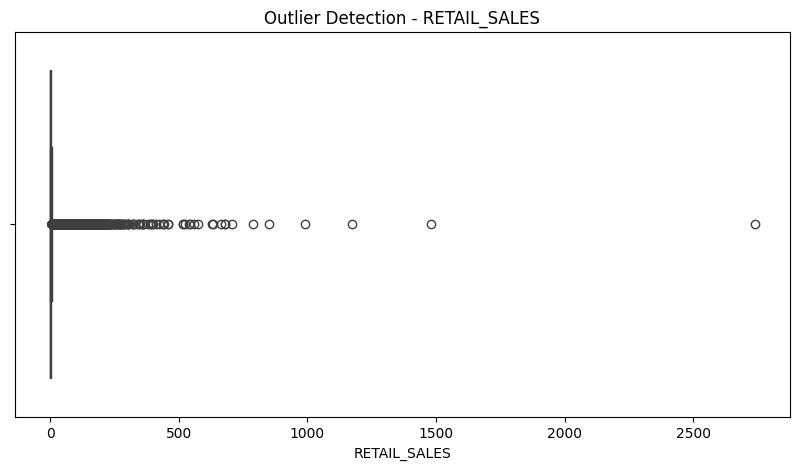

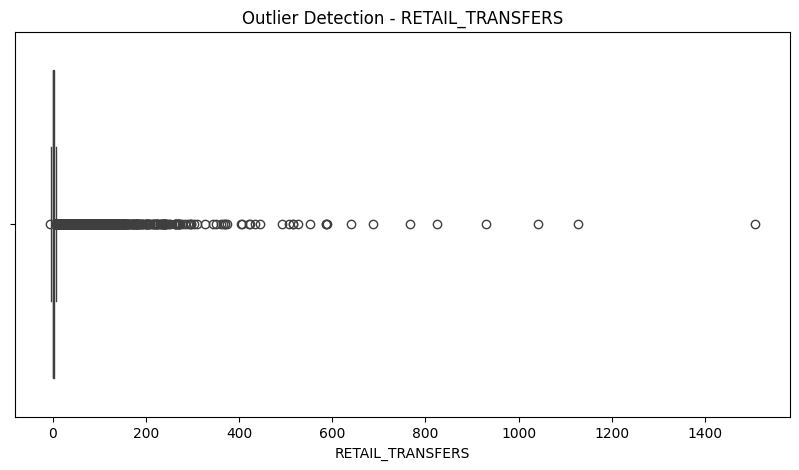

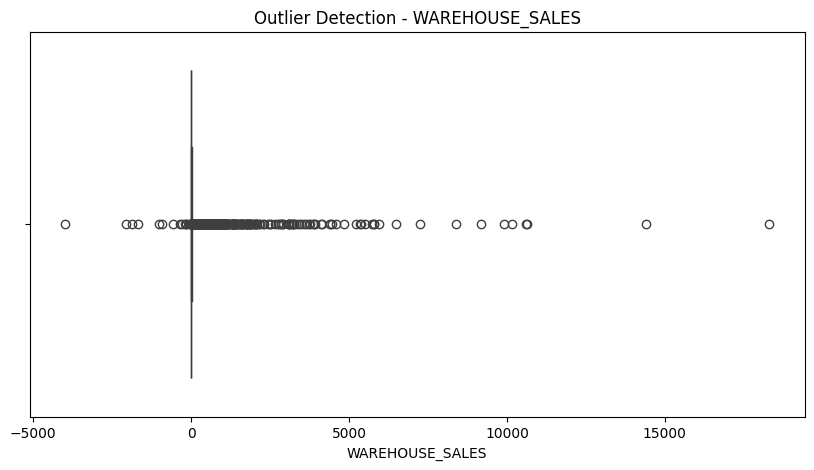

In [82]:
for col in ["RETAIL_SALES", "RETAIL_TRANSFERS", "WAREHOUSE_SALES"]:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Detection - {col}")
    plt.xlabel(col)
    plt.show()

# 35. Distribution Analysis

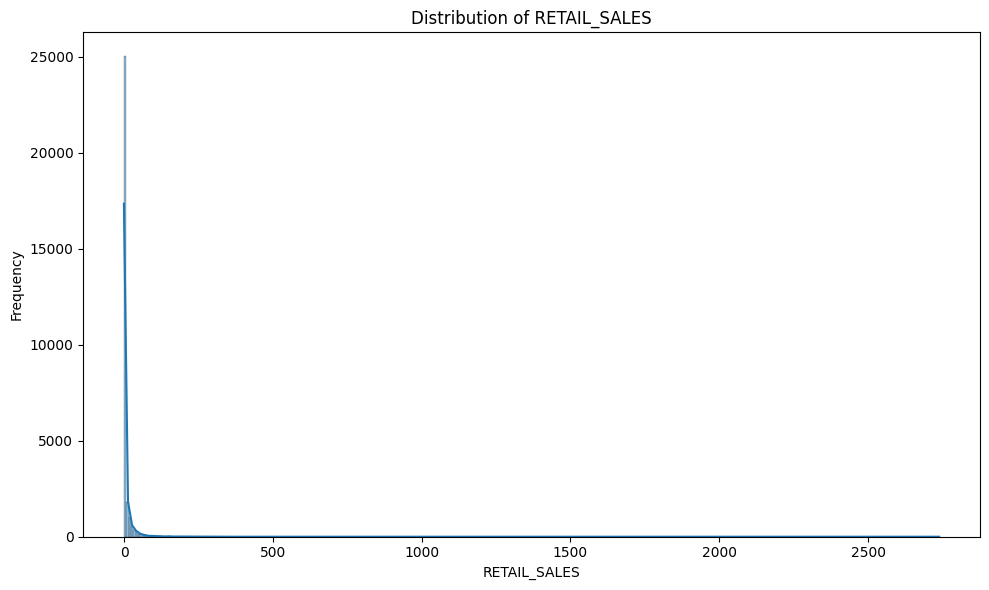

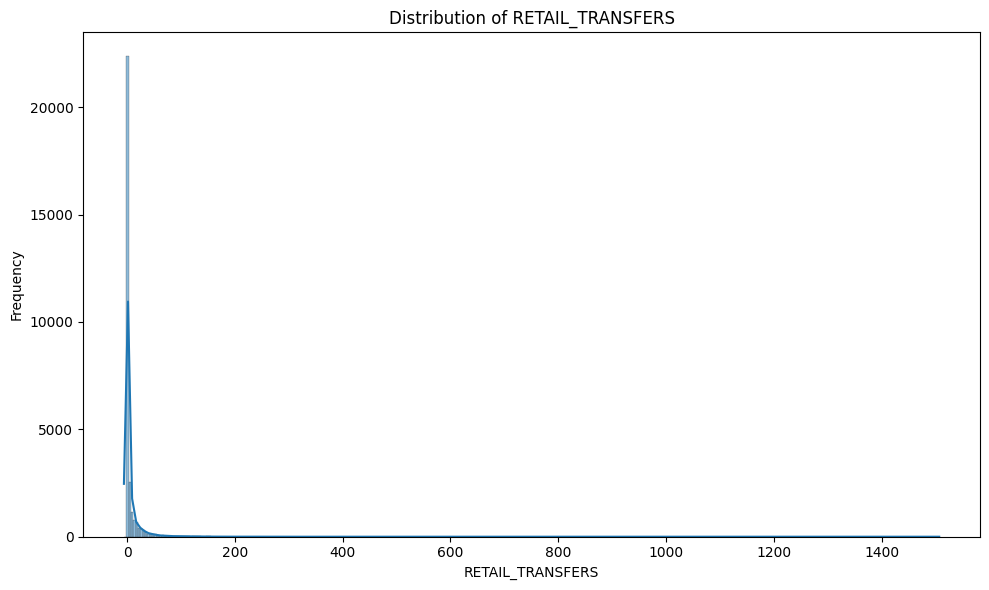

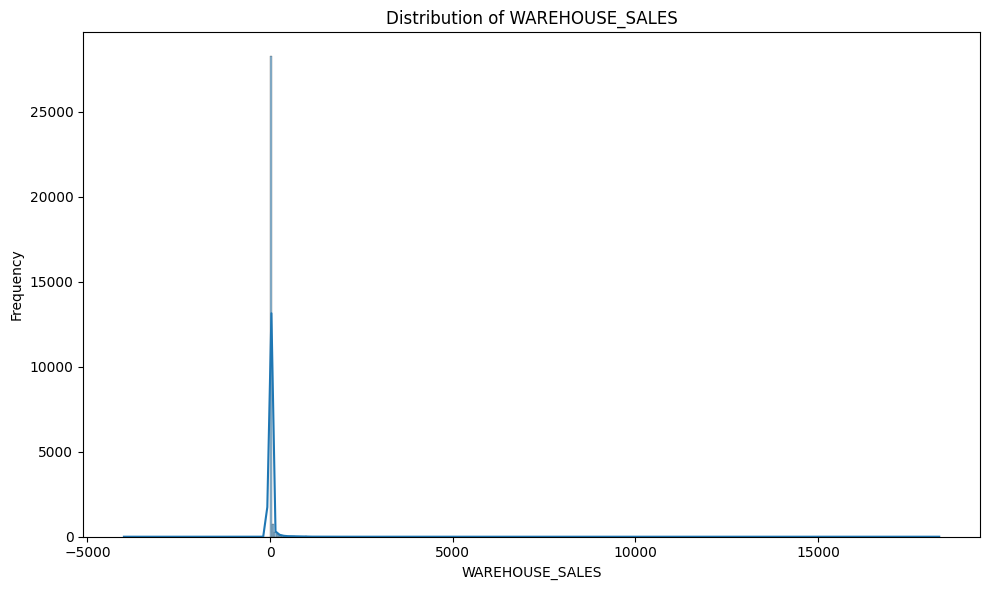

In [83]:
for col in ["RETAIL_SALES", "RETAIL_TRANSFERS", "WAREHOUSE_SALES"]:
    plt.figure(figsize=(10, 6))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# 36. Supplier Risk Analysis

In [84]:
supplier_risk = supplier.copy()
supplier_risk["Risk_Level"] = np.where(
    supplier_risk["Contribution_%"] >= 5,
    "HIGH",
    np.where(supplier_risk["Contribution_%"] >= 2, "MEDIUM", "LOW")
)
display(supplier_risk[
    ["SUPPLIER", "TOTAL_ACTIVITY", "Contribution_%", "Risk_Level"]
].head(20))

,SUPPLIER,TOTAL_ACTIVITY,Contribution_%,Risk_Level
0,0.00,"1,228,939.61",100.00,HIGH


# 37. Product Performance Classification

In [85]:
sku_performance = sku.copy()

def classify_product(x):
    if x >= 5:
        return "A - High Performer"
    elif x >= 1:
        return "B - Medium Performer"
    else:
        return "C - Low Performer"

sku_performance["Performance"] = sku_performance["Contribution_%"].apply(classify_product)
display(sku_performance[
    ["ITEM_CODE", "ITEM_DESCRIPTION", "TOTAL_ACTIVITY", "Contribution_%", "Performance"]
].head(30))

,ITEM_CODE,ITEM_DESCRIPTION,TOTAL_ACTIVITY,Contribution_%,Performance
0,23445,CORONA EXTRA LOOSE NR - 12OZ,"49,109.50",4.00,B - Medium Performer
1,23886,HEINEKEN LOOSE NR - 12OZ,"26,792.88",2.18,B - Medium Performer
2,96750,CORONA EXTRA 2/12 NR - 12OZ,"21,082.50",1.72,B - Medium Performer
3,25883,MODELO ESPECIAL 24 LOOSE NR - 12OZ,"20,970.00",1.71,B - Medium Performer
4,96970,HEINEKEN 2/12 NR - 12OZ,"15,936.40",1.30,B - Medium Performer
5,90590,MILLER LITE 30PK CAN - 12OZ,"13,459.40",1.10,B - Medium Performer
6,23777,MODELO ESPECIAL SUITCASE CANS - 12OZ,"13,092.84",1.07,B - Medium Performer
7,23314,CORONA EXTRA 18PK NR - 12OZ,"10,973.72",0.89,C - Low Performer
8,96741,CORONA EXTRA 4/6 NR - 12OZ,"10,380.04",0.84,C - Low Performer
9,90468,BUD LIGHT 30PK CAN,"10,362.97",0.84,C - Low Performer


# 38. Create Automated Business Insights

In [86]:
top_category = category.iloc[0]["ITEM_TYPE"]
top_category_share = category.iloc[0]["Contribution_%"]
top_supplier = supplier.iloc[0]["SUPPLIER"]
top_supplier_activity = supplier.iloc[0]["TOTAL_ACTIVITY"]
top_product = sku.iloc[0]["ITEM_DESCRIPTION"]
top_product_activity = sku.iloc[0]["TOTAL_ACTIVITY"]

print("\n" + "=" * 70)
print("AUTOMATED BUSINESS INSIGHTS")
print("=" * 70)
print(f"1. {top_category} is the largest category, contributing {top_category_share:.2f}% of total activity.")
print(f"2. {top_supplier} is the largest supplier, with {top_supplier_activity:,.2f} units of activity.")
print(f"3. {top_product} is the highest-performing SKU, with {top_product_activity:,.2f} units.")
print(f"4. Warehouse sales represent {total_warehouse / total_activity * 100:.2f}% of total activity.")
print(f"5. The top 5 suppliers represent {top5_supplier_share:.2f}% of total activity.")


AUTOMATED BUSINESS INSIGHTS
1. BEER is the largest category, contributing 66.12% of total activity.
2. 0.0 is the largest supplier, with 1,228,939.61 units of activity.
3. CORONA EXTRA LOOSE NR - 12OZ is the highest-performing SKU, with 49,109.50 units.
4. Warehouse sales represent 66.96% of total activity.
5. The top 5 suppliers represent 100.00% of total activity.


# 39. Create a Final Data Analysis Report

In [87]:
final_report = pd.DataFrame({
    "KPI": [
        "Total Records", "Total Activity", "Retail Sales", "Retail Transfers",
        "Warehouse Sales", "Unique Suppliers", "Unique SKUs", "Unique Categories",
        "Top Category", "Top Supplier", "Top SKU", "Top 5 Supplier Share %",
        "Retail Sales vs Transfers Correlation"
    ],
    "Value": [
        len(df), total_activity, total_retail_sales, total_transfers,
        total_warehouse, unique_suppliers, unique_items, unique_categories,
        top_category, top_supplier, top_product, top5_supplier_share,
        retail_transfer_corr
    ]
})
display(final_report)

,KPI,Value
0,Total Records,30000
1,Total Activity,"1,228,939.61"
2,Retail Sales,"208,186.94"
3,Retail Transfers,"197,821.74"
4,Warehouse Sales,"822,930.93"
5,Unique Suppliers,1
6,Unique SKUs,15668
7,Unique Categories,8
8,Top Category,BEER
9,Top Supplier,0.00


# 40. Export All Analysis Results to Excel

In [88]:
output_file = "/content/Retail_Sales_Data_Analysis.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    final_report.to_excel(
        writer,
        sheet_name="Executive_KPIs",
        index=False
    )

    monthly.to_excel(
        writer,
        sheet_name="Monthly_Analysis",
        index=False
    )

    category.to_excel(
        writer,
        sheet_name="Category_Analysis",
        index=False
    )

    supplier.to_excel(
        writer,
        sheet_name="Supplier_Analysis",
        index=False
    )

    sku.to_excel(
        writer,
        sheet_name="SKU_Analysis",
        index=False
    )

    zero_analysis.to_excel(
        writer,
        sheet_name="Zero_Activity",
        index=False
    )

    negative_analysis.to_excel(
        writer,
        sheet_name="Negative_Transactions",
        index=False
    )

print("Excel report created successfully:")
print(output_file)


Excel report created successfully:
/content/Retail_Sales_Data_Analysis.xlsx
